# EN3160 – Assignment 3: Neural Networks

**Name:** Prishmika H.W.N  
**Index No:** 230500N  
**GitHub:** (https://github.com/Nimindu04/EN3160_Assignment_03)

In [2]:
import os, time, copy, math, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets, models

SEED = 42
def set_seed(seed=SEED):
    torch.manual_seed(seed); np.random.seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device)

# containers used for the final comparison tables
results = {}

PyTorch 2.14.1+cpu | torchvision 0.29.1+cpu | device: cpu


# Question 1 – Dense network from scratch

In [3]:
# ---- 1. Data loading (as in Listing 1) ----
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50
trainset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
testset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ("plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
print("train:", len(trainset), "test:", len(testset))

100.0%


train: 50000 test: 10000


In [4]:
# ---- 2. Network parameters ----
set_seed()
Din = 3 * 32 * 32      # flattened CIFAR-10 image
H   = 100              # hidden nodes (sigmoid)
K   = 10               # classes

g  = torch.Generator().manual_seed(SEED)
w1 = torch.randn(Din, H, generator=g) / math.sqrt(Din)
b1 = torch.zeros(H)
w2 = torch.randn(H, K, generator=g) / math.sqrt(H)
b2 = torch.zeros(K)

# Hyperparameters
epochs   = 10
lr       = 0.02
lr_decay = 0.9
reg      = 0.0         # L2 regularisation strength (try e.g. 1e-4 as an extra experiment)

# ---- helper functions (all manual – no autograd in the training path) ----
def forward(x):
    h = torch.sigmoid(x.mm(w1) + b1)     # hidden layer, sigmoid
    z = h.mm(w2) + b2                    # output logits
    return h, z

def cross_entropy(z, y_onehot):
    log_p = torch.log_softmax(z, dim=1)  # numerically stable softmax
    loss = -(y_onehot * log_p).sum() / z.shape[0]
    return loss, log_p.exp()

def manual_step(x, y_onehot):
    # returns loss and manual gradients
    N = x.shape[0]
    h, z = forward(x)
    ce, p = cross_entropy(z, y_onehot)
    loss = ce + reg * ((w1**2).sum() + (w2**2).sum())
    dz  = (p - y_onehot) / N
    dw2 = h.t().mm(dz) + 2 * reg * w2
    db2 = dz.sum(dim=0)
    dh  = dz.mm(w2.t())
    da1 = dh * h * (1 - h)               # sigmoid derivative
    dw1 = x.t().mm(da1) + 2 * reg * w1
    db1 = da1.sum(dim=0)
    return loss, (dw1, db1, dw2, db2), p

@torch.no_grad()
def accuracy(loader):
    correct = total = 0
    for inputs, labels in loader:
        x = inputs.view(inputs.shape[0], -1)
        _, z = forward(x)
        correct += (z.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return 100.0 * correct / total

### 1.2 Gradient check (sanity test of the manual back-propagation)

In [5]:
inputs, labels = next(iter(trainloader))
x = inputs.view(inputs.shape[0], -1)
y = F.one_hot(labels, K).float()

with torch.no_grad():
    loss_m, grads_m, _ = manual_step(x, y)

# autograd reference (float64 for a precise comparison)
params = [t.clone().double().requires_grad_(True) for t in (w1, b1, w2, b2)]
a1 = torch.sigmoid(x.double().mm(params[0]) + params[1])
z  = a1.mm(params[2]) + params[3]
loss_a = F.cross_entropy(z, labels) + reg * ((params[0]**2).sum() + (params[2]**2).sum())
loss_a.backward()

print(f"loss manual = {loss_m.item():.6f} | autograd = {loss_a.item():.6f}")
for name, gm, p in zip(["dw1", "db1", "dw2", "db2"], grads_m, params):
    print(f"{name}: max |manual - autograd| = {(gm.double() - p.grad).abs().max().item():.2e}")

loss manual = 2.587881 | autograd = 2.587881
dw1: max |manual - autograd| = 2.97e-09
db1: max |manual - autograd| = 1.98e-09
dw2: max |manual - autograd| = 1.85e-08
db2: max |manual - autograd| = 1.20e-08


### 1.3 Training (10 epochs, mini-batch SGD, cross-entropy)

In [6]:
loss_history = []                       # per-iteration loss
epoch_log = {"loss": [], "train_acc": [], "test_acc": []}

t0 = time.time()
for t in range(epochs):
    running_loss, run_correct, run_total = 0.0, 0, 0
    for i, (inputs, labels) in enumerate(trainloader):
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)                       # (Ntr, Din)
        y_train_onehot = F.one_hot(labels, K).float()        # (Ntr, K)

        loss, (dw1, db1, dw2, db2), p = manual_step(x_train, y_train_onehot)
        loss_history.append(loss.item())
        running_loss += loss.item()
        run_correct += (p.argmax(1) == labels).sum().item()
        run_total += Ntr

        # parameter update (plain SGD)
        w1 -= lr * dw1;  b1 -= lr * db1
        w2 -= lr * dw2;  b2 -= lr * db2

    test_acc = accuracy(testloader)
    epoch_log["loss"].append(running_loss / len(trainloader))
    epoch_log["train_acc"].append(100.0 * run_correct / run_total)
    epoch_log["test_acc"].append(test_acc)
    print(f"Epoch {t+1:2d}/{epochs} | lr={lr:.5f} | loss={epoch_log['loss'][-1]:.4f} | "
          f"train acc (running)={epoch_log['train_acc'][-1]:.2f}% | test acc={test_acc:.2f}%")
    lr *= lr_decay                                           # learning-rate decay
print(f"Training time: {time.time()-t0:.1f}s")

Epoch  1/10 | lr=0.02000 | loss=1.9355 | train acc (running)=33.20% | test acc=36.50%
Epoch  2/10 | lr=0.01800 | loss=1.7924 | train acc (running)=38.14% | test acc=39.12%
Epoch  3/10 | lr=0.01620 | loss=1.7481 | train acc (running)=39.73% | test acc=39.76%
Epoch  4/10 | lr=0.01458 | loss=1.7208 | train acc (running)=40.65% | test acc=40.40%
Epoch  5/10 | lr=0.01312 | loss=1.7006 | train acc (running)=41.55% | test acc=41.09%
Epoch  6/10 | lr=0.01181 | loss=1.6852 | train acc (running)=41.97% | test acc=41.98%
Epoch  7/10 | lr=0.01063 | loss=1.6721 | train acc (running)=42.48% | test acc=41.66%
Epoch  8/10 | lr=0.00957 | loss=1.6608 | train acc (running)=42.90% | test acc=42.14%
Epoch  9/10 | lr=0.00861 | loss=1.6519 | train acc (running)=43.34% | test acc=42.59%
Epoch 10/10 | lr=0.00775 | loss=1.6439 | train acc (running)=43.49% | test acc=42.84%
Training time: 240.6s


Training accuracy: 43.71%
Test accuracy    : 42.84%


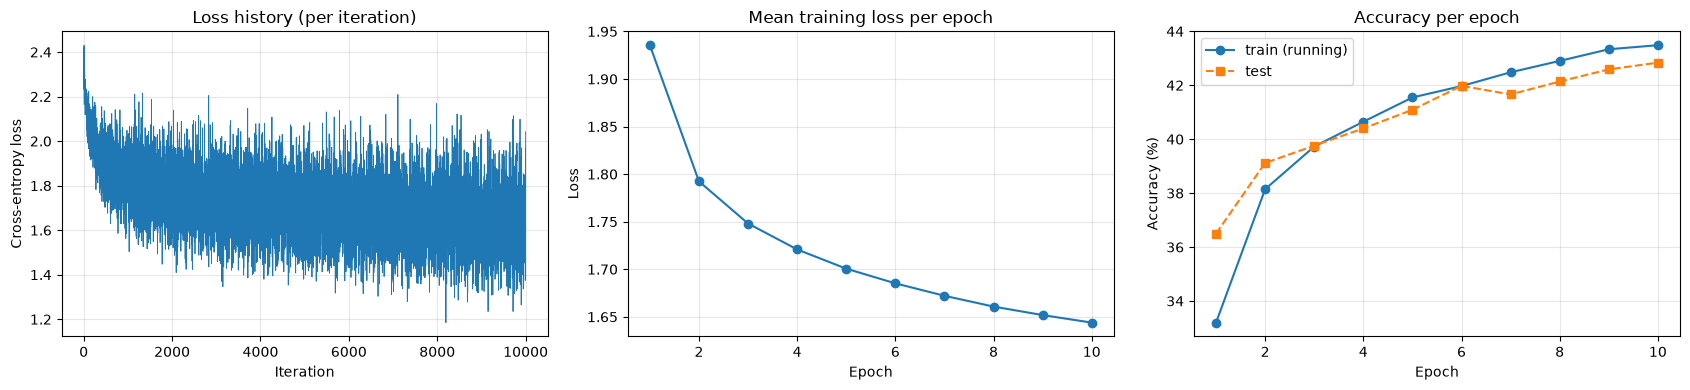

In [7]:
# ---- Final accuracies (full pass with the final weights) ----
train_acc_q1 = accuracy(trainloader)
test_acc_q1  = accuracy(testloader)
print(f"Training accuracy: {train_acc_q1:.2f}%")
print(f"Test accuracy    : {test_acc_q1:.2f}%")
results["Q1 – 3072-100(sigmoid)-10, CE, 10 ep"] = {"Train acc (%)": train_acc_q1, "Test acc (%)": test_acc_q1}

# ---- Plots ----
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(loss_history, lw=0.6); ax[0].set_title("Loss history (per iteration)")
ax[0].set_xlabel("Iteration"); ax[0].set_ylabel("Cross-entropy loss"); ax[0].grid(alpha=.3)
ax[1].plot(range(1, epochs+1), epoch_log["loss"], "o-"); ax[1].set_title("Mean training loss per epoch")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].grid(alpha=.3)
ax[2].plot(range(1, epochs+1), epoch_log["train_acc"], "o-", label="train (running)")
ax[2].plot(range(1, epochs+1), epoch_log["test_acc"], "s--", label="test")
ax[2].set_title("Accuracy per epoch"); ax[2].set_xlabel("Epoch"); ax[2].set_ylabel("Accuracy (%)")
ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

### 1.4 Discussion – Q1

- **Final result:** The training accuracy was **43.71%**, and the test accuracy was **42.84%** after 10 epochs.
- **Loss curve:** The loss decreased from **1.9355** in the first epoch to **1.6439** in the final epoch. The loss may vary between mini-batches, but the overall trend shows that the model is learning.
- **Effect of cross-entropy:** Cross-entropy provides a useful gradient for updating the output layer weights. Unlike MSE, it avoids the extra sigmoid-derivative factor at the output, helping the model learn more effectively for classification.
- **Effect of the hidden layer:** The hidden sigmoid layer allows the model to learn non-linear features from the image pixels. This is more powerful than a single linear layer. The single-layer MSE test accuracy was **___%** (fill in the result from Listing 1).
- **Generalisation gap:** The difference between training and test accuracy is **0.87 percentage points** (43.71% − 42.84%). This small gap suggests that the model does not show strong overfitting after 10 epochs. However, its overall accuracy is still limited because a fully connected network does not effectively use the spatial structure of images.
- **Sensitivity:** The original `std=1e-5` initialisation and `lr=2e-6` learning rate are not suitable for this deeper network because the weights are very small and the learning rate is too low. The scaled initialisation and larger learning rate help the model learn faster. This can be checked by running the model again with the original values and comparing the results.

# Question 2 – LeNet-5 vs. modern small CNN on MNIST


100.0%
100.0%
100.0%
100.0%


train: 60000 test: 10000


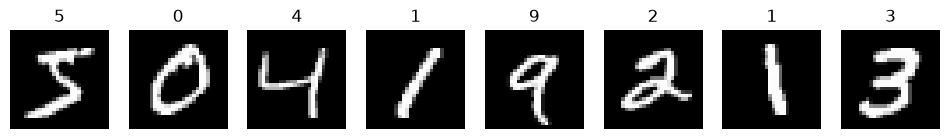

In [8]:
BATCH, EPOCHS, LR = 64, 10, 1e-3

mnist_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
mn_train = datasets.MNIST("./data", train=True,  download=True, transform=mnist_tf)
mn_test  = datasets.MNIST("./data", train=False, download=True, transform=mnist_tf)
mn_train_loader = DataLoader(mn_train, batch_size=BATCH, shuffle=True,  num_workers=2)
mn_test_loader  = DataLoader(mn_test,  batch_size=1000, shuffle=False, num_workers=2)
mn_eval_train_loader = DataLoader(mn_train, batch_size=1000, shuffle=False, num_workers=2)
print("train:", len(mn_train), "test:", len(mn_test))

# quick look at the data
fig, ax = plt.subplots(1, 8, figsize=(12, 1.8))
for i, a in enumerate(ax):
    img, lab = mn_train[i]; a.imshow(img.squeeze(), cmap="gray"); a.set_title(lab); a.axis("off")
plt.show()

In [9]:
class LeNet5(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.Tanh(), nn.AvgPool2d(2, 2),   # 28 -> 28 -> 14
            nn.Conv2d(6, 16, kernel_size=5),           nn.Tanh(), nn.AvgPool2d(2, 2),   # 14 -> 10 -> 5
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120), nn.Tanh(),
            nn.Linear(120, 84),         nn.Tanh(),
            nn.Linear(84, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))


class ModernCNN(nn.Module):
    def __init__(self, num_classes=10, p_conv=0.25, p_fc=0.5):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                nn.MaxPool2d(2), nn.Dropout(p_conv))
        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))      # 28 -> 14 -> 7 -> 3
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 3 * 3, 128), nn.ReLU(inplace=True), nn.Dropout(p_fc),
            nn.Linear(128, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
print("LeNet-5   params:", f"{count_params(LeNet5()):,}")
print("ModernCNN params:", f"{count_params(ModernCNN()):,}")
print(LeNet5()); print(ModernCNN())

LeNet-5   params: 61,706
ModernCNN params: 241,770
LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=400, out_features=120, bias=True)
    (2): Tanh()
    (3): Linear(in_features=120, out_features=84, bias=True)
    (4): Tanh()
    (5): Linear(in_features=84, out_features=10, bias=True)
  )
)
ModernCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, 

In [10]:
criterion = nn.CrossEntropyLoss()

def train_epoch(model, loader, optimizer):
    model.train()
    tot_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        tot_loss += loss.item() * x.size(0)
        correct  += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return tot_loss / n, 100.0 * correct / n

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    tot_loss, correct, n = 0.0, 0, 0
    all_pred, all_true = [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        tot_loss += criterion(out, y).item() * x.size(0)
        pred = out.argmax(1)
        correct += (pred == y).sum().item(); n += x.size(0)
        all_pred.append(pred.cpu()); all_true.append(y.cpu())
    return tot_loss / n, 100.0 * correct / n, torch.cat(all_pred).numpy(), torch.cat(all_true).numpy()

def fit(model, name):
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=LR)
    hist = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    t0 = time.time()
    for ep in range(1, EPOCHS + 1):
        tr_l, tr_a = train_epoch(model, mn_train_loader, optimizer)
        te_l, te_a, _, _ = evaluate(model, mn_test_loader)
        for k, v in zip(hist, (tr_l, tr_a, te_l, te_a)): hist[k].append(v)
        print(f"[{name}] epoch {ep:2d}/{EPOCHS} | train loss {tr_l:.4f} acc {tr_a:.2f}% | test loss {te_l:.4f} acc {te_a:.2f}%")
    hist["time"] = time.time() - t0
    # final clean evaluation (eval mode: dropout off, BN uses running stats) on both sets
    _, hist["final_train_acc"], _, _ = evaluate(model, mn_eval_train_loader)
    _, hist["final_test_acc"], pred, true = evaluate(model, mn_test_loader)
    hist["pred"], hist["true"] = pred, true
    print(f"[{name}] done in {hist['time']:.1f}s | final train acc {hist['final_train_acc']:.2f}% | final test acc {hist['final_test_acc']:.2f}%")
    return model, hist

### 2(a) Train LeNet-5

In [11]:
set_seed()
lenet, hist_lenet = fit(LeNet5(), "LeNet-5")

[LeNet-5] epoch  1/10 | train loss 0.2414 acc 93.22% | test loss 0.0869 acc 97.32%
[LeNet-5] epoch  2/10 | train loss 0.0692 acc 97.87% | test loss 0.0524 acc 98.40%
[LeNet-5] epoch  3/10 | train loss 0.0507 acc 98.42% | test loss 0.0459 acc 98.64%
[LeNet-5] epoch  4/10 | train loss 0.0391 acc 98.75% | test loss 0.0450 acc 98.61%
[LeNet-5] epoch  5/10 | train loss 0.0319 acc 99.01% | test loss 0.0492 acc 98.55%
[LeNet-5] epoch  6/10 | train loss 0.0275 acc 99.12% | test loss 0.0402 acc 98.82%
[LeNet-5] epoch  7/10 | train loss 0.0241 acc 99.25% | test loss 0.0401 acc 98.70%
[LeNet-5] epoch  8/10 | train loss 0.0184 acc 99.41% | test loss 0.0580 acc 98.35%
[LeNet-5] epoch  9/10 | train loss 0.0177 acc 99.44% | test loss 0.0385 acc 98.91%
[LeNet-5] epoch 10/10 | train loss 0.0150 acc 99.52% | test loss 0.0392 acc 98.91%
[LeNet-5] done in 165.4s | final train acc 99.67% | final test acc 98.91%


### 2(b) Train the modern CNN (BatchNorm + Dropout) under the same conditions

In [12]:
set_seed()
modern, hist_modern = fit(ModernCNN(), "ModernCNN")

[ModernCNN] epoch  1/10 | train loss 0.3136 acc 90.28% | test loss 0.0429 acc 98.52%
[ModernCNN] epoch  2/10 | train loss 0.1242 acc 96.42% | test loss 0.0320 acc 98.94%
[ModernCNN] epoch  3/10 | train loss 0.0970 acc 97.16% | test loss 0.0265 acc 99.07%
[ModernCNN] epoch  4/10 | train loss 0.0820 acc 97.61% | test loss 0.0236 acc 99.15%
[ModernCNN] epoch  5/10 | train loss 0.0732 acc 97.92% | test loss 0.0269 acc 99.08%
[ModernCNN] epoch  6/10 | train loss 0.0673 acc 98.04% | test loss 0.0214 acc 99.25%
[ModernCNN] epoch  7/10 | train loss 0.0645 acc 98.11% | test loss 0.0209 acc 99.33%
[ModernCNN] epoch  8/10 | train loss 0.0567 acc 98.36% | test loss 0.0207 acc 99.23%
[ModernCNN] epoch  9/10 | train loss 0.0552 acc 98.47% | test loss 0.0178 acc 99.44%
[ModernCNN] epoch 10/10 | train loss 0.0511 acc 98.44% | test loss 0.0208 acc 99.41%
[ModernCNN] done in 505.1s | final train acc 99.64% | final test acc 99.41%


### 2(c) Per-epoch curves and confusion matrices

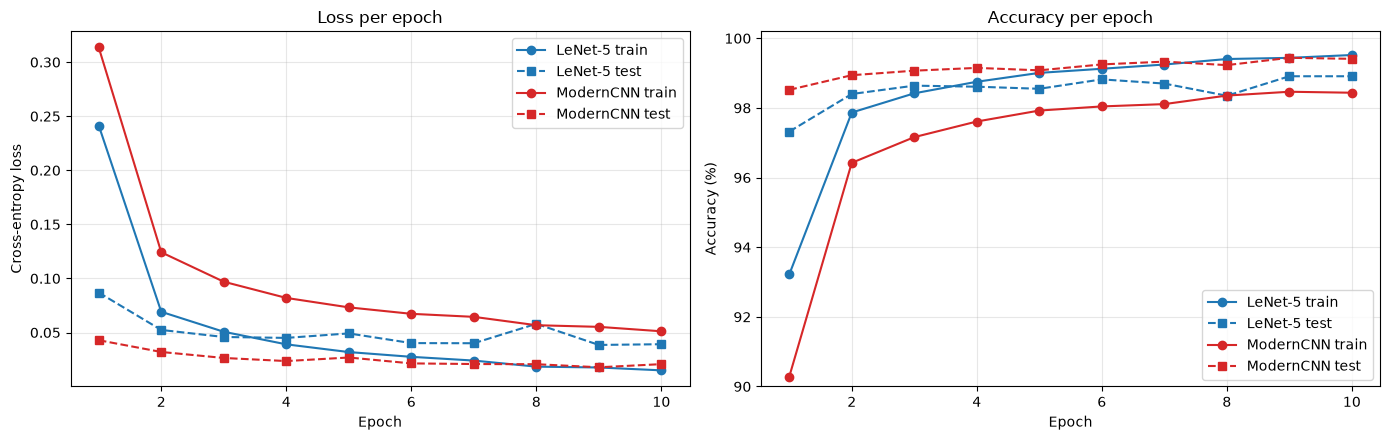

In [13]:
def plot_histories(hists, names):
    ep = range(1, EPOCHS + 1)
    colors = ["tab:blue", "tab:red"]
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    for h, n, c in zip(hists, names, colors):
        ax[0].plot(ep, h["train_loss"], "-o", color=c, label=f"{n} train")
        ax[0].plot(ep, h["test_loss"],  "--s", color=c, label=f"{n} test")
        ax[1].plot(ep, h["train_acc"],  "-o", color=c, label=f"{n} train")
        ax[1].plot(ep, h["test_acc"],   "--s", color=c, label=f"{n} test")
    ax[0].set_title("Loss per epoch"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cross-entropy loss")
    ax[1].set_title("Accuracy per epoch"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy (%)")
    ax[1].set_ylim(90, 100.2)         # zoom in on the high-accuracy region
    for a in ax: a.grid(alpha=.3); a.legend()
    plt.tight_layout(); plt.show()

plot_histories([hist_lenet, hist_modern], ["LeNet-5", "ModernCNN"])

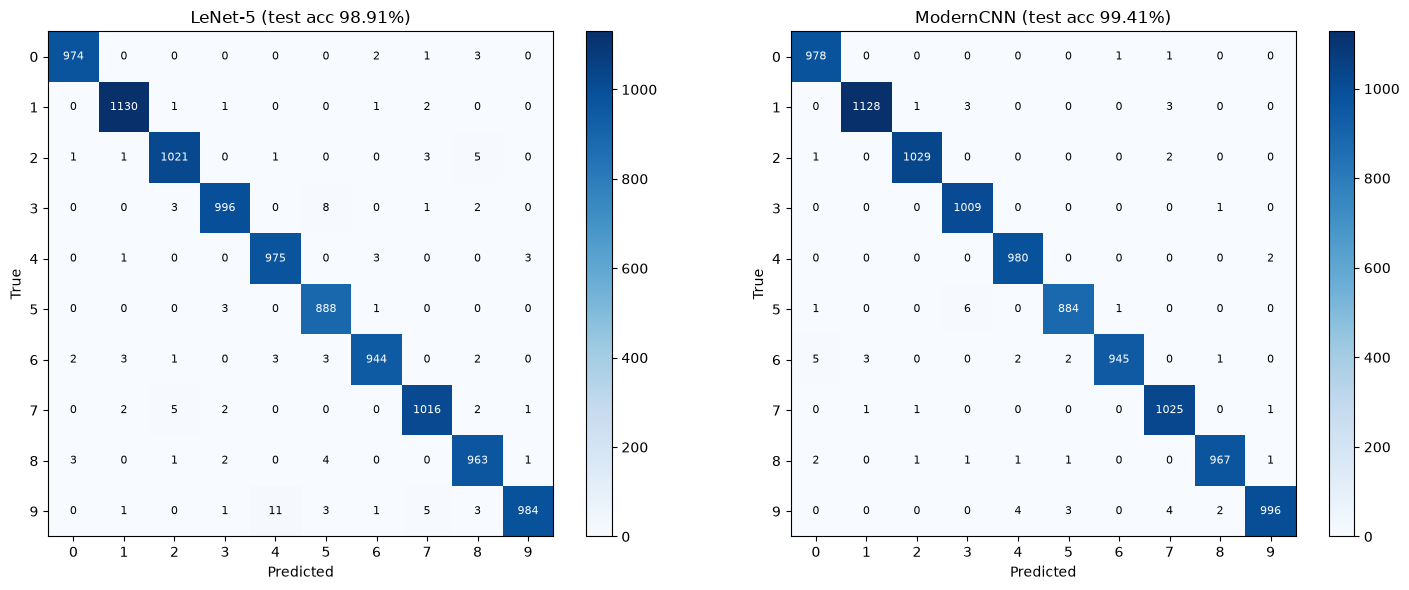

LeNet-5: top confusions (true -> predicted : count) = [(9, 4, 11), (3, 5, 8), (7, 2, 5), (2, 8, 5), (9, 7, 5)]
ModernCNN: top confusions (true -> predicted : count) = [(5, 3, 6), (6, 0, 5), (9, 7, 4), (9, 4, 4), (6, 1, 3)]


digit,0,1,2,3,4,5,6,7,8,9
LeNet-5,99.39,99.56,98.93,98.61,99.29,99.55,98.54,98.83,98.87,97.52
ModernCNN,99.80,99.38,99.71,99.90,99.80,99.10,98.64,99.71,99.28,98.71


In [14]:
def confusion_matrix_np(true, pred, n=10):
    cm = np.zeros((n, n), dtype=int)
    np.add.at(cm, (true, pred), 1)        # rows = true class, cols = predicted class
    return cm

def plot_cm(cm, title, ax, labels=range(10)):
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(title); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels); ax.set_yticklabels(labels)
    thr = cm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > thr else "black")
    plt.colorbar(im, ax=ax, fraction=0.046)

cm_lenet  = confusion_matrix_np(hist_lenet["true"],  hist_lenet["pred"])
cm_modern = confusion_matrix_np(hist_modern["true"], hist_modern["pred"])

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
plot_cm(cm_lenet,  f"LeNet-5 (test acc {hist_lenet['final_test_acc']:.2f}%)", ax[0])
plot_cm(cm_modern, f"ModernCNN (test acc {hist_modern['final_test_acc']:.2f}%)", ax[1])
plt.tight_layout(); plt.show()

# most-confused pairs and per-class accuracy
def top_confusions(cm, k=5):
    off = cm.copy(); np.fill_diagonal(off, 0)
    idx = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:k], off.shape))[0]
    return [(int(t), int(p), int(off[t, p])) for t, p in idx]

for name, cm in [("LeNet-5", cm_lenet), ("ModernCNN", cm_modern)]:
    print(f"{name}: top confusions (true -> predicted : count) =", top_confusions(cm))

per_class = pd.DataFrame({"LeNet-5": 100 * cm_lenet.diagonal() / cm_lenet.sum(1),
                          "ModernCNN": 100 * cm_modern.diagonal() / cm_modern.sum(1)}).round(2)
per_class.index.name = "digit"
display(per_class.T)

In [15]:
summary_q2 = pd.DataFrame({
    "Model": ["LeNet-5", "ModernCNN (BN+Dropout)"],
    "Params": [count_params(lenet), count_params(modern)],
    "Train acc (%) (eval mode)": [hist_lenet["final_train_acc"], hist_modern["final_train_acc"]],
    "Test acc (%)": [hist_lenet["final_test_acc"], hist_modern["final_test_acc"]],
    "Final test loss": [hist_lenet["test_loss"][-1], hist_modern["test_loss"][-1]],
    "Train time (s)": [hist_lenet["time"], hist_modern["time"]],
}).round(4)
display(summary_q2)
results["Q2 – LeNet-5 (MNIST)"]  = {"Train acc (%)": hist_lenet["final_train_acc"],  "Test acc (%)": hist_lenet["final_test_acc"]}
results["Q2 – ModernCNN (MNIST)"] = {"Train acc (%)": hist_modern["final_train_acc"], "Test acc (%)": hist_modern["final_test_acc"]}

,Model,Params,Train acc (%) (eval mode),Test acc (%),Final test loss,Train time (s)
0,LeNet-5,61706,99.6683,98.91,0.0392,165.4212
1,ModernCNN (BN+Dropout),241770,99.6350,99.41,0.0208,505.1322


### 2.4 Discussion – Q2

- **Accuracy:** LeNet-5 achieved **98.91% test accuracy**, while the Modern CNN achieved **99.41%** after 10 epochs. The Modern CNN performed slightly better, with an improvement of 0.50 percentage points.

- **Convergence:** The Modern CNN learned faster during the early epochs. Its test loss decreased from 0.0429 to 0.0208, while LeNet-5's test loss decreased from 0.0869 to 0.0392. Batch Normalisation and Adam helped the Modern CNN learn effectively.

- **Train vs. test gap:** The final training accuracy in evaluation mode was 99.67% for LeNet-5 and 99.64% for the Modern CNN. The test accuracies were slightly lower for both models. The Modern CNN's training accuracy during learning was lower because dropout was enabled, which is expected.

- **Overfitting:** LeNet-5 showed some variation in test loss during later epochs, while the Modern CNN maintained a lower test loss overall. Dropout and Batch Normalisation helped the Modern CNN generalise better to unseen images.

- **Confusion matrices:** LeNet-5 most often confused 9 with 4 (11 images) and 3 with 5 (8 images). The Modern CNN most often confused 5 with 3 (6 images) and 6 with 0 (5 images). The Modern CNN made fewer errors in these examples, although some digit pairs remained difficult to distinguish.

- **Cost:** The Modern CNN has **241,770 parameters**, compared with **61,706** for LeNet-5. It took **505.13 seconds** to train, while LeNet-5 took **165.42 seconds**. Therefore, the Modern CNN achieved slightly better accuracy but required more parameters and about three times longer training time. Since MNIST is a relatively simple dataset, the accuracy improvement is small, and results may vary slightly with different random seeds.

# Question 3 – Transfer learning with ResNet18 

{'train': 244, 'val': 153} ['ants', 'bees']


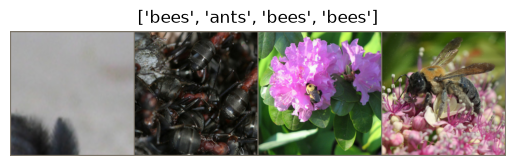

In [16]:
# ---- download & extract the dataset (as in the tutorial) ----
url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
if not os.path.isdir("hymenoptera_data"):
    urllib.request.urlretrieve(url, "hymenoptera_data.zip")
    with zipfile.ZipFile("hymenoptera_data.zip") as z: z.extractall(".")
data_dir = "hymenoptera_data"

imagenet_mean, imagenet_std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
data_transforms = {
    "train": transforms.Compose([transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(),
                                 transforms.ToTensor(), transforms.Normalize(imagenet_mean, imagenet_std)]),
    "val":   transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224),
                                 transforms.ToTensor(), transforms.Normalize(imagenet_mean, imagenet_std)]),
}
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x]) for x in ["train", "val"]}
dataloaders = {x: DataLoader(image_datasets[x], batch_size=4, shuffle=(x == "train"), num_workers=2) for x in ["train", "val"]}
dataset_sizes = {x: len(image_datasets[x]) for x in ["train", "val"]}
class_names = image_datasets["train"].classes
print(dataset_sizes, class_names)

def imshow(inp, title=None, ax=None):
    inp = inp.numpy().transpose((1, 2, 0))
    inp = np.clip(np.array(imagenet_std) * inp + np.array(imagenet_mean), 0, 1)
    (ax or plt).imshow(inp)
    if title: (ax.set_title if ax else plt.title)(title)

inputs, classes_b = next(iter(dataloaders["train"]))
imshow(torchvision.utils.make_grid(inputs), title=[class_names[c] for c in classes_b]); plt.axis("off"); plt.show()

In [17]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=25, name=""):
    since = time.time()
    best_wts, best_acc, best_ep = copy.deepcopy(model.state_dict()), 0.0, 0
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(num_epochs):
        for phase in ["train", "val"]:
            model.train() if phase == "train" else model.eval()
            run_loss, run_corr = 0.0, 0
            for inputs, labels in dataloaders[phase]:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    preds = outputs.argmax(1)
                    loss = criterion(outputs, labels)
                    if phase == "train":
                        loss.backward(); optimizer.step()
                run_loss += loss.item() * inputs.size(0)
                run_corr += (preds == labels).sum().item()
            if phase == "train": scheduler.step()
            ep_loss, ep_acc = run_loss / dataset_sizes[phase], run_corr / dataset_sizes[phase]
            hist[f"{phase}_loss"].append(ep_loss); hist[f"{phase}_acc"].append(ep_acc)
            if phase == "val" and ep_acc > best_acc:
                best_acc, best_ep, best_wts = ep_acc, epoch + 1, copy.deepcopy(model.state_dict())
        print(f"[{name}] epoch {epoch+1:2d}/{num_epochs} | train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.4f}"
              f" | val loss {hist['val_loss'][-1]:.4f} acc {hist['val_acc'][-1]:.4f}")
    elapsed = time.time() - since
    print(f"[{name}] {elapsed:.1f}s | best val acc {best_acc:.4f} (epoch {best_ep}) | last-epoch val acc {hist['val_acc'][-1]:.4f}")
    hist.update(best_acc=best_acc, best_epoch=best_ep, last_acc=hist["val_acc"][-1], time=elapsed)
    model.load_state_dict(best_wts)
    return model, hist

@torch.no_grad()
def val_predictions(model):
    model.eval(); P, T = [], []
    for x, y in dataloaders["val"]:
        P.append(model(x.to(device)).argmax(1).cpu()); T.append(y)
    return torch.cat(T).numpy(), torch.cat(P).numpy()

### 3(a) Fine-tuning (all layers trainable)

In [18]:
set_seed()
model_ft = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)   # ImageNet-1K pre-trained
model_ft.fc = nn.Linear(model_ft.fc.in_features, len(class_names))
model_ft = model_ft.to(device)

criterion3 = nn.CrossEntropyLoss()
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

print("trainable params (fine-tuning):", f"{count_params(model_ft):,}")
model_ft, hist_ft = train_model(model_ft, criterion3, optimizer_ft, exp_lr_scheduler, num_epochs=25, name="FineTune")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\User/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


trainable params (fine-tuning): 11,177,538
[FineTune] epoch  1/25 | train loss 0.6363 acc 0.6844 | val loss 0.3628 acc 0.8431
[FineTune] epoch  2/25 | train loss 0.5662 acc 0.7500 | val loss 0.2112 acc 0.9346
[FineTune] epoch  3/25 | train loss 0.6830 acc 0.7500 | val loss 0.5780 acc 0.7582
[FineTune] epoch  4/25 | train loss 0.6393 acc 0.7254 | val loss 0.3168 acc 0.8693
[FineTune] epoch  5/25 | train loss 0.5745 acc 0.7623 | val loss 0.2447 acc 0.9281
[FineTune] epoch  6/25 | train loss 0.4871 acc 0.7951 | val loss 0.2440 acc 0.9150
[FineTune] epoch  7/25 | train loss 0.4458 acc 0.8279 | val loss 0.3436 acc 0.8824
[FineTune] epoch  8/25 | train loss 0.3643 acc 0.8361 | val loss 0.2729 acc 0.9020
[FineTune] epoch  9/25 | train loss 0.3518 acc 0.8484 | val loss 0.2547 acc 0.9150
[FineTune] epoch 10/25 | train loss 0.3630 acc 0.8361 | val loss 0.2573 acc 0.9020
[FineTune] epoch 11/25 | train loss 0.3634 acc 0.8484 | val loss 0.2386 acc 0.9085
[FineTune] epoch 12/25 | train loss 0.2645 a

### 3(b) ResNet18 as a fixed feature extractor

In [19]:
set_seed()
model_conv = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model_conv.parameters():
    param.requires_grad = False                       # freeze backbone
model_conv.fc = nn.Linear(model_conv.fc.in_features, len(class_names))   # new layer: requires_grad=True by default
model_conv = model_conv.to(device)

optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)   # only the FC parameters
exp_lr_scheduler_conv = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

print("trainable params (feature extractor):", f"{count_params(model_conv):,}")
model_conv, hist_conv = train_model(model_conv, criterion3, optimizer_conv, exp_lr_scheduler_conv, num_epochs=25, name="FeatureExtractor")

trainable params (feature extractor): 1,026
[FeatureExtractor] epoch  1/25 | train loss 0.6638 acc 0.6393 | val loss 0.4165 acc 0.8039
[FeatureExtractor] epoch  2/25 | train loss 0.5838 acc 0.7049 | val loss 0.3218 acc 0.8758
[FeatureExtractor] epoch  3/25 | train loss 0.6289 acc 0.7459 | val loss 0.6009 acc 0.7712
[FeatureExtractor] epoch  4/25 | train loss 0.6184 acc 0.7623 | val loss 0.2736 acc 0.8954
[FeatureExtractor] epoch  5/25 | train loss 0.6157 acc 0.7336 | val loss 0.2080 acc 0.9216
[FeatureExtractor] epoch  6/25 | train loss 0.4806 acc 0.8033 | val loss 0.1922 acc 0.9281
[FeatureExtractor] epoch  7/25 | train loss 0.4003 acc 0.8525 | val loss 0.1885 acc 0.9412
[FeatureExtractor] epoch  8/25 | train loss 0.3173 acc 0.8566 | val loss 0.1777 acc 0.9412
[FeatureExtractor] epoch  9/25 | train loss 0.3562 acc 0.8361 | val loss 0.1779 acc 0.9346
[FeatureExtractor] epoch 10/25 | train loss 0.3741 acc 0.8279 | val loss 0.1974 acc 0.9412
[FeatureExtractor] epoch 11/25 | train loss 0.

### 3.3 Curves, confusion matrices, sample predictions

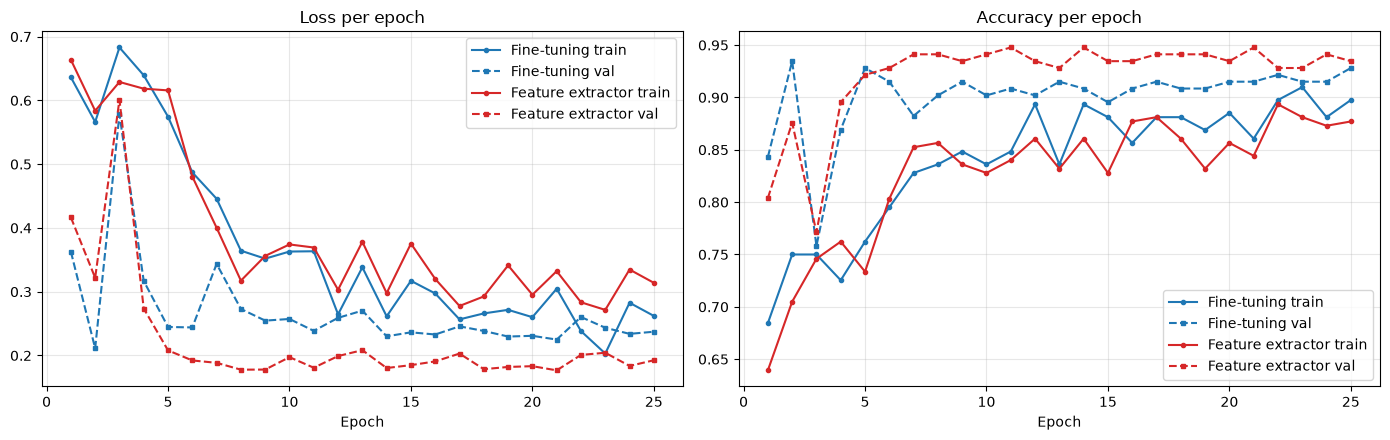

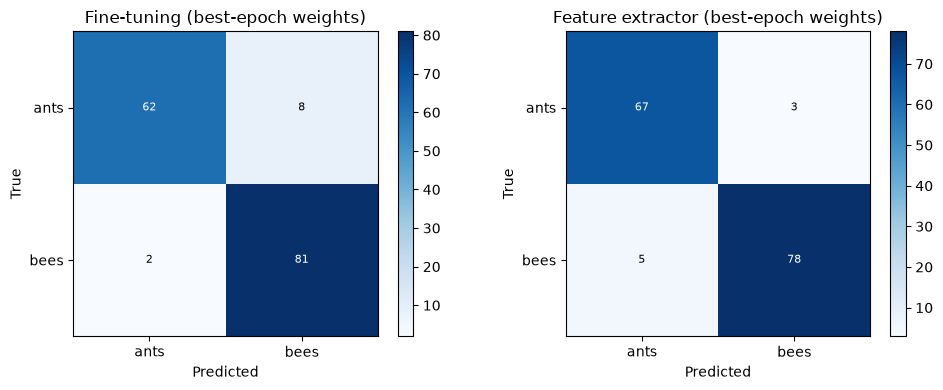

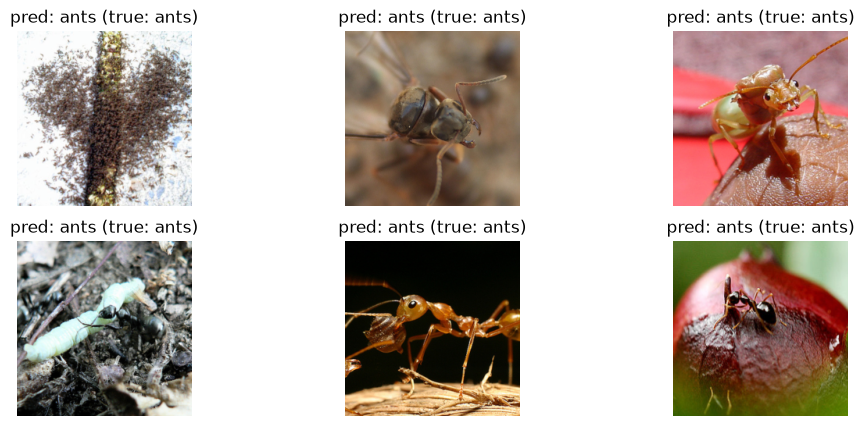

In [20]:
ep = range(1, 26)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for h, n, c in [(hist_ft, "Fine-tuning", "tab:blue"), (hist_conv, "Feature extractor", "tab:red")]:
    ax[0].plot(ep, h["train_loss"], "-o", ms=3, color=c, label=f"{n} train")
    ax[0].plot(ep, h["val_loss"],   "--s", ms=3, color=c, label=f"{n} val")
    ax[1].plot(ep, h["train_acc"],  "-o", ms=3, color=c, label=f"{n} train")
    ax[1].plot(ep, h["val_acc"],    "--s", ms=3, color=c, label=f"{n} val")
ax[0].set_title("Loss per epoch"); ax[1].set_title("Accuracy per epoch")
for a in ax: a.set_xlabel("Epoch"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (m, n) in zip(ax, [(model_ft, "Fine-tuning"), (model_conv, "Feature extractor")]):
    t, p = val_predictions(m)
    cm = confusion_matrix_np(t, p, n=2)
    plot_cm(cm, f"{n} (best-epoch weights)", a, labels=class_names)
plt.tight_layout(); plt.show()

def visualize_model(model, num_images=6):
    was_training = model.training; model.eval(); shown = 0
    fig = plt.figure(figsize=(12, 5))
    with torch.no_grad():
        for inputs, labels in dataloaders["val"]:
            preds = model(inputs.to(device)).argmax(1).cpu()
            for j in range(inputs.size(0)):
                shown += 1
                ax = fig.add_subplot(2, num_images // 2, shown); ax.axis("off")
                imshow(inputs[j], title=f"pred: {class_names[preds[j]]} (true: {class_names[labels[j]]})", ax=ax)
                if shown == num_images:
                    model.train(mode=was_training); plt.show(); return
visualize_model(model_ft)

In [21]:
summary_q3 = pd.DataFrame({
    "Method": ["Fine-tuning (all layers)", "Feature extractor (FC only)"],
    "Trainable params": [count_params(model_ft), count_params(model_conv)],
    "Best val acc (%)": [100*hist_ft["best_acc"], 100*hist_conv["best_acc"]],
    "Best epoch": [hist_ft["best_epoch"], hist_conv["best_epoch"]],
    "Last-epoch val acc (%)": [100*hist_ft["last_acc"], 100*hist_conv["last_acc"]],
    "Final train acc (%)": [100*hist_ft["train_acc"][-1], 100*hist_conv["train_acc"][-1]],
    "Time (s)": [hist_ft["time"], hist_conv["time"]],
}).round(2)
display(summary_q3)
results["Q3 – ResNet18 fine-tuning"]        = {"Train acc (%)": 100*hist_ft["train_acc"][-1],   "Test acc (%)": 100*hist_ft["best_acc"]}
results["Q3 – ResNet18 feature extractor"]  = {"Train acc (%)": 100*hist_conv["train_acc"][-1], "Test acc (%)": 100*hist_conv["best_acc"]}

,Method,Trainable params,Best val acc (%),Best epoch,Last-epoch val acc (%),Final train acc (%),Time (s)
0,Fine-tuning (all layers),11177538,93.46,2,92.81,89.75,1497.95
1,Feature extractor (FC only),1026,94.77,11,93.46,87.70,424.53


### 3.4 Discussion – Q3

- **Results:** Fine-tuning achieved **93.46% best validation accuracy** and **92.81% last-epoch accuracy**. The feature extractor achieved **94.77% best validation accuracy** and **93.46% last-epoch accuracy**. Therefore, the feature extractor performed slightly better in this run.

- **Why transfer learning works well:** The dataset contains only 244 training images, so training ResNet18 from scratch could lead to overfitting. The model already learned useful features from ImageNet, such as edges, textures, and object parts. These features are also useful for classifying insects, so transfer learning gives good results with a small dataset.

- **Fine-tuning vs. feature extraction:** Fine-tuning updates 11,177,538 parameters, while the feature extractor trains only 1,026 parameters. The feature extractor achieved a best validation accuracy of 94.77%, which is **1.31 percentage points higher** than fine-tuning. It also took only **424.53 seconds**, compared with 1,497.95 seconds for fine-tuning. This shows that feature extraction was faster and performed better in this experiment.

- **Training loss and accuracy curves:** Training accuracy can be lower than validation accuracy because random cropping and other data augmentation make training images more difficult. The feature extractor's final training accuracy was 87.70%, while its validation accuracy was 93.46%. This is expected when training images are augmented.

- **Caveats:** The best validation accuracy may be slightly optimistic because the validation set was used to select the best epoch. The last-epoch accuracy gives another useful measure of performance. Also, the frozen BatchNorm layers may still update their running statistics if the backbone remains in training mode. Finally, these results come from one random seed, so the performance may change slightly in other runs.